#### **Feature Engineering & Polynomial Regression**

In [31]:
import numpy as np
import matplotlib.pyplot as plt

# Data

# House Size
X = np.array([1, 2, 3, 4, 5, 6, 7, 8, 9, 10])

# House Price
y = np.array([3, 7, 13, 21, 31, 43, 57, 73, 91, 111])

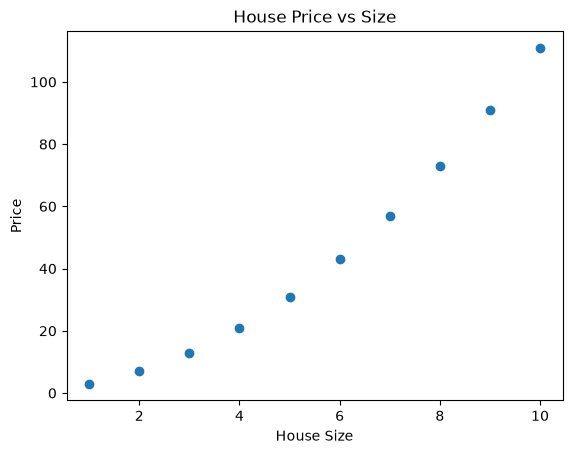

In [32]:
plt.scatter(X, y)
plt.xlabel("House Size")
plt.ylabel("Price")

plt.title("House Price vs Size")
plt.show()

Now we are going to introduce two more fearures that are made using the existing information eg. We can calculate Area using the two sides of a square shaped house, Area = X * X = X^2

In [33]:
X_poly = np.column_stack((
    X,
    X**2,
    X**3
))
print(X_poly)
print(X_poly.shape)

[[   1    1    1]
 [   2    4    8]
 [   3    9   27]
 [   4   16   64]
 [   5   25  125]
 [   6   36  216]
 [   7   49  343]
 [   8   64  512]
 [   9   81  729]
 [  10  100 1000]]
(10, 3)


X^2 and X^3 are engineered features

Reusing the previous functions 
- predict_all()
- cost_function()
- gradient()
- gradient_descent()

In [34]:
mean = np.mean(X_poly, axis=0)
std = np.std(X_poly, axis=0)

X_poly_scaled = (X_poly - mean) / std

print("Scaled Features:\n", X_poly_scaled)

Scaled Features:
 [[-1.5666989  -1.15669692 -0.92459328]
 [-1.21854359 -1.06416117 -0.90312676]
 [-0.87038828 -0.90993491 -0.84486052]
 [-0.52223297 -0.69401815 -0.73139468]
 [-0.17407766 -0.41641089 -0.54432937]
 [ 0.17407766 -0.07711313 -0.26526474]
 [ 0.52223297  0.32387514  0.1241991 ]
 [ 0.87038828  0.78655391  0.64246199]
 [ 1.21854359  1.31092318  1.30792382]
 [ 1.5666989   1.89698295  2.13898444]]


In [35]:
def predict_all(X, w, b):
    return np.dot(X, w) + b

In [36]:
def cost_function(X, y, w, b):

    m = X.shape[0]

    predictions = predict_all(X, w, b)

    errors = predictions - y
    squared_errors = errors ** 2
    
    total_cost = np.sum(squared_errors) / (2 * m)

    return total_cost

In [37]:
def gradient(X, y, w, b):
    m, n = X.shape

    predictions = predict_all(X, w, b)

    errors = predictions - y
    dj_dw = np.dot(X.T, errors) * (1/ m)
    dj_db = np.sum(errors) / m

    return dj_dw, dj_db

In [38]:
def gradient_descent(X, y, w, b, a, iterations):

    costs = []

    for i in range(iterations):

        dj_dw, dj_db = gradient(X, y, w, b)

        w = w - a * dj_dw
        b = b - a * dj_db
        cost = cost_function(X, y, w, b)
        costs.append(cost)

    return costs, w, b

In [39]:
# Training model

w = np.zeros(X_poly_scaled.shape[1])
b = 0.0

a = 0.3
iterations = 50000

cost_history, final_w, final_b = gradient_descent(X_poly_scaled, y, w, b, a, iterations)

print("Final weights:", final_w)
print("Final bias:", final_b)
print("Final cost:", cost_history[-1])

Final weights: [2.87255777e+00 3.24192428e+01 3.93629543e-04]
Final bias: 45.0
Final cost: 2.2912941892821346e-10


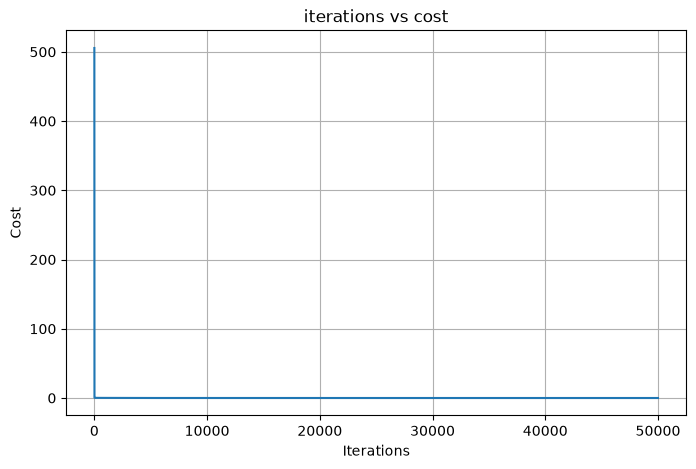

In [40]:
plt.figure(figsize=(8,5))
plt.plot(cost_history)
plt.xlabel("Iterations")
plt.ylabel("Cost")
plt.title("iterations vs cost")

plt.grid(True)
plt.show()

In [41]:
predictions = predict_all(X_poly_scaled, final_w, final_b)

print("Actual values:", y)
print("Predicted values:", predictions)

Actual values: [  3   7  13  21  31  43  57  73  91 111]
Predicted values: [  2.99996457   7.00000834  13.00002597  21.00002471  31.0000118
  42.99999448  56.99998     72.9999756   90.99998852 111.00002601]


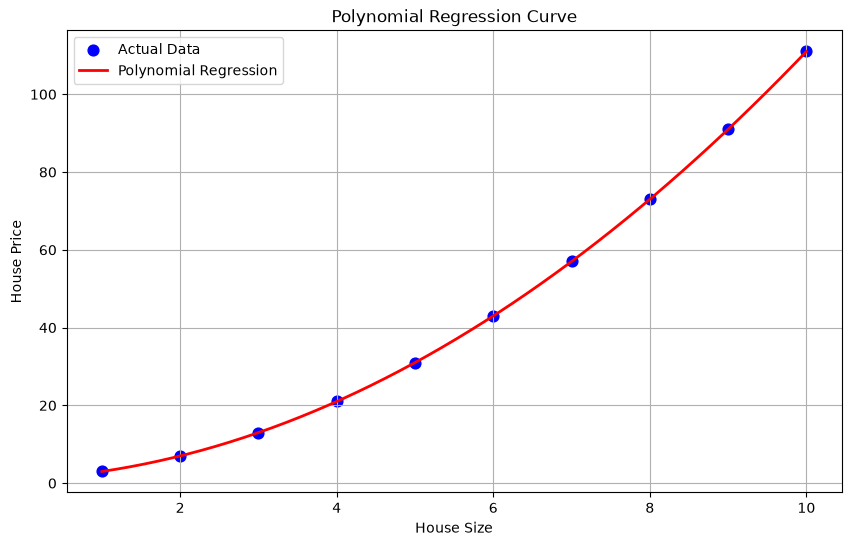

In [ ]:
X_curve = np.linspace(1, 10, 200)

X_curve_poly = np.column_stack((
    X_curve,
    X_curve**2,
    X_curve**3
))

X_curve_scaled = (X_curve_poly - mean) / std

curve_predictions = predict_all(X_curve_scaled,final_w,final_b)

plt.figure(figsize=(10, 6))

plt.scatter(X, y, color='blue',label='Actual Data', s=60)

plt.plot(X_curve, curve_predictions,color='red', linewidth=2,label='Polynomial Regression')

plt.xlabel('House Size')
plt.ylabel('House Price')
plt.title('Polynomial Regression Curve')

plt.legend()
plt.grid(True)
plt.show()